In [38]:
import requests
from IPython.core.display import HTML

# Activation functions and loss functions
This exercise is about activation- and loss functions for neural architectures. The architecture of an NN offers endless variations and customization possibilities for defining (families of) prediction functions, making it impractical to exhaustively test every possible option for a given problem. Consequently, developing an intuition of how different architectural choices, parameters, and hyperparameters impact the performance of the network is essential. 

**Important**
Most of the code is provided, with only a few adjustments left to complete, it is however important for you to reflect on the outcomes and **relate them to the theory**.


<article class="message">
    <div class="message-body">
        <strong>List of individual tasks</strong>
        <ul style="list-style: none;">
            <li>
            <a href="#activation">Task 1: Implement activation functions</a>
            </li>
            <li>
            <a href="#activation1">Task 2: Experiment with activation functions</a>
            </li>
            <li>
            <a href="#activation2">Task 3: Evaluate</a>
            </li>
            <li>
            <a href="#loss">Task 4: Implement loss functions</a>
            </li>
            <li>
            <a href="#loss1">Task 5: Visualizing loss functions</a>
            </li>
            <li>
            <a href="#loss2">Task 6: Experiment with loss functions</a>
            </li>
            <li>
            <a href="#loss3">Task 7: Evaluate</a>
            </li>
            <li>
            <a href="#loss4">Task 8: Custom loss functions</a>
            </li>
        </ul>
    </div>
</article>

## Activation Functions
This exercise is about the importance of selecting an appropriate activation function. Activation functions are crucial for introducing non-linearity into neural architectures. Each activation function has its unique characteristics and trade-offs and can significantly influence the model’s predictive capability, impacting its performance, convergence behavior, and the complexity of tasks it can effectively address.
This exercise explores activation functions for:
**Classification:**
- Sigmoid: Commonly used in binary classification tasks, the sigmoid function maps input values to a number between 0 and 1. However, it can suffer from so-called vanishing gradient problems, occurring in deeper networks.

- Hyperbolic Tangent (tanh): maps inputs to the range between -1 and 1 and addresses some of the shortcomings of the sigmoid function in terms of vanishing gradients.

- Softmax: is a generalization of the logistic function, commonly used for the output layer of multi-class classification networks, converting raw inputs into probabilities across multiple classes.


**Regression:**
- Rectified Linear Unit (ReLU): ReLU introduces non-linearity while maintaining computational efficiency. It helps mitigate vanishing gradient issues but may encounter "dead neurons" due to zero gradients for negative inputs.

- Leaky ReLU: addresses the "dying ReLU" problem by allowing a small, non-zero gradients for negative inputs, maintaining active neurons during training.

- Exponential Linear Unit (ELU): similar to ReLU for positive inputs, ELU applies an exponential function to negative values, ensuring smoother gradients and reducing the risk of “dead neurons” during trainin



---
**Task 1 (medium): Implement activation functions👩‍💻**
1. Use the `torch`
 library to implement the activation functions defined in the cell below. 


**Activation functions**
**Linear**

$$
f(x) = x
$$
**Sigmoid**

$$
f(x) = \frac{1}{1 + e^{-x}}
$$
**ReLU**

$$
f(x) = \max(0, x)
$$
**Leaky ReLU**

$$
f(x) = \begin{cases} 
x & \text{if } x > 0 \\
\alpha x & \text{if } x \leq 0 
\end{cases}
$$
**Tanh**

$$
f(x) = \tanh(x) = \frac{e^x - e^{-x}}{e^x + e^{-x}}
$$
**ELU**

$$
f(x) = \begin{cases} 
x & \text{for } x \geq 0 \\
\alpha \left( e^x - 1 \right) & \text{for } x < 0
\end{cases}
$$



---

In [39]:
import torch

# f(x) = x
# outputs the same value as the input
def linear(x):
    return x

# used for binary classification
# outputs a value between 0 and 1 (probability)
# prone to vanishing gradient problems
def sigmoid(x):
    return torch.sigmoid(x)
    
# used for general regression
# outputs the value if positive, else 0
# prone to dead neurons because of the zero 
def relu(x):
    return torch.nn.functional.relu(x)
    
# used for general regression
# outputs the value if positive, else 0.01 * the value to prevent dead neurons
def leaky_relu(x, alpha=0.01):
    return torch.nn.functional.relu(x)

# used for tasks reguiring values centered around 0
# outputs values between -1 and 1
# smooth gradient
def tanh(x):
    return torch.tanh(x)

# used for regression where smoother gradient is needed
# outputs between -1 and infinity
# smooth gradient
def elu(x, alpha=1.0):
    return torch.nn.functional.relu(x)
    

## Applying activation functions to neural networks
<div style="float: right; width: 50%; justify-content: start" class="block is-clearfix">

<div class="has-text-centered">
<figure class="image is-inline-block" id="make_moons">

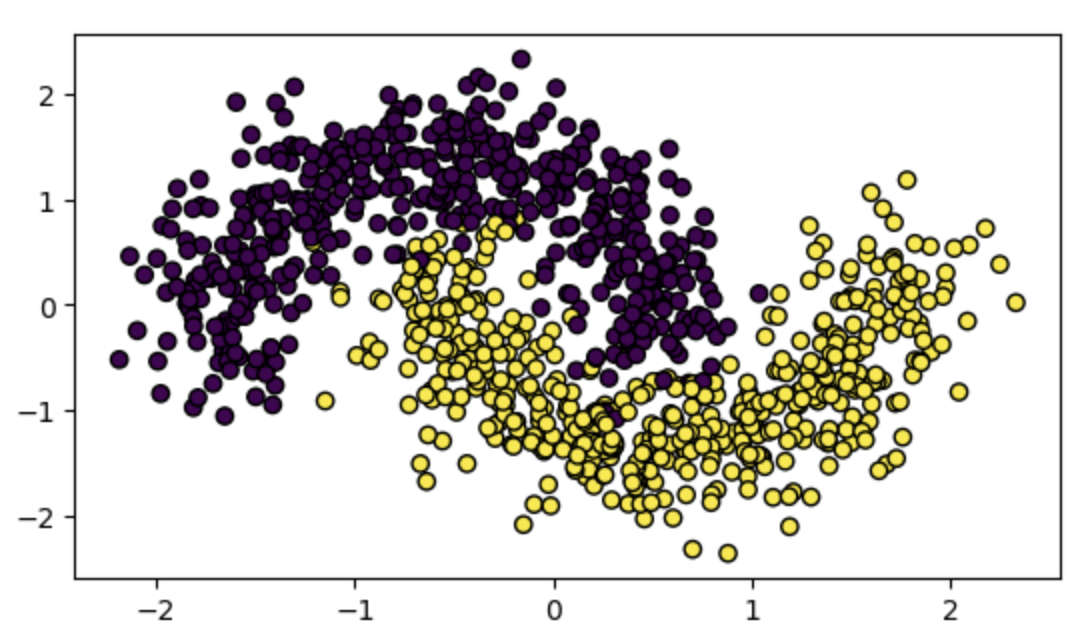

<figcaption class="figure-caption has-text-center">Figure 1: Example of the synthetic data generated by the `make_moons`
 function.
</figcaption>
</figure>
</div>


</div>

The `make_moons`
 function from the [Scikit-Learn Library](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html)
 is used to generate synthetic data. The function generates two classes to be separated as shown in [Figure 1](#make_moons). The following tasks will apply the activation functions for the classification problem to:
- train neural networks (NNs), 
- evaluate their effects on performance, focusing on accuracy, convergence speed, and computational efficiency.

The NN defined in the cell below uses functions and classes defined in the following files:
- `networks.py`
: Contains the `SimpleNN`
 network implementation.
- `trainers.py`
: contains the `train`
 function used for training.
- `metrics.py`
: contains the `evaluateNN`
 function for evaluation and visualization.


---
**Task 2 (medium): Experiment with activation functions👩‍💻**
1. Examine the files and gain an overview of the architecture of the NN and the training loop. 

2. Run the cell below to train and visualize the performance of the models with the different activations functions.



---

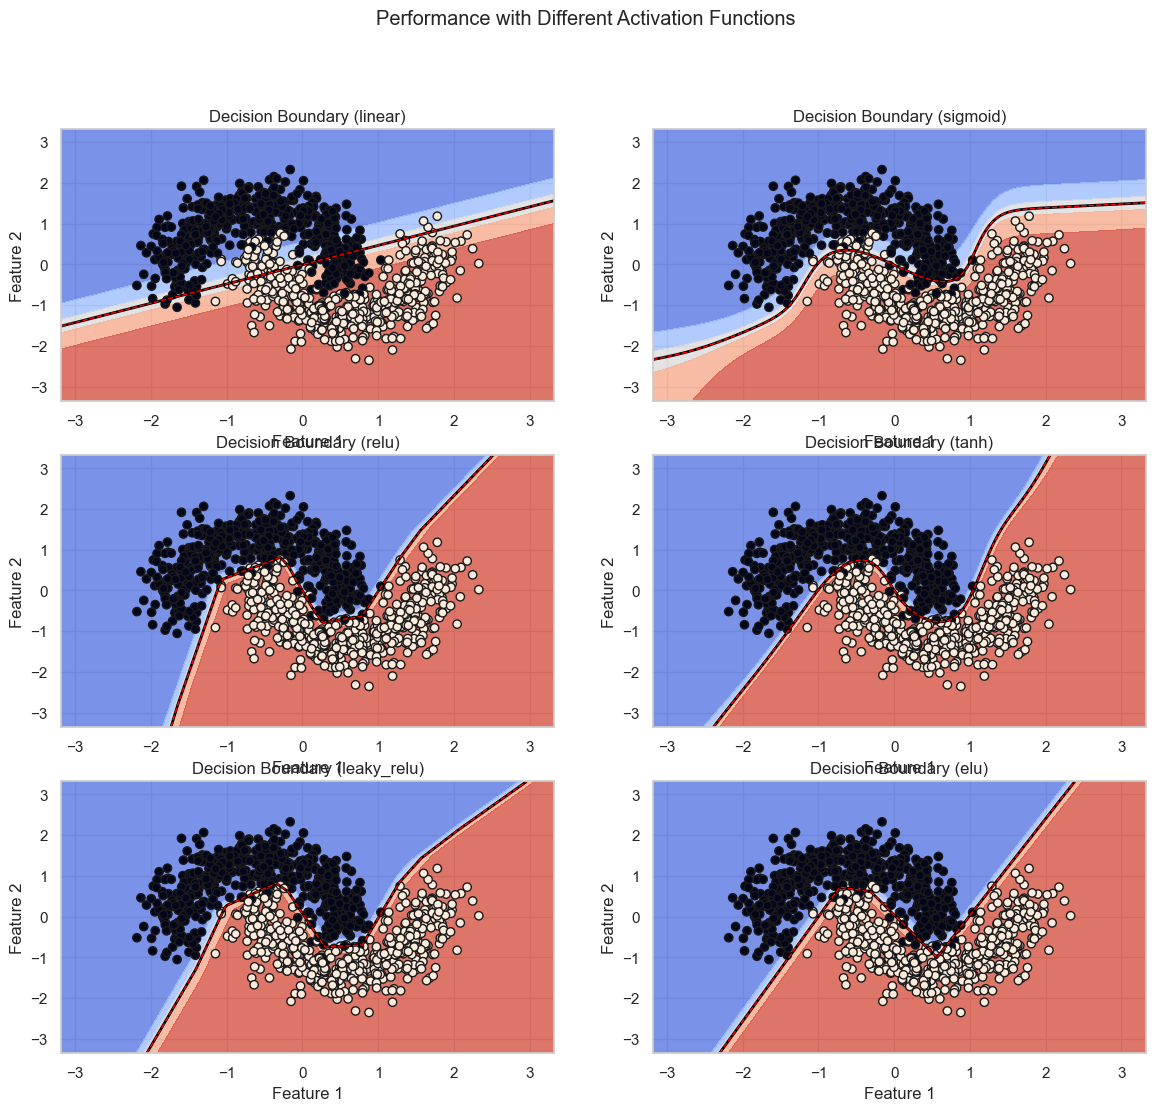

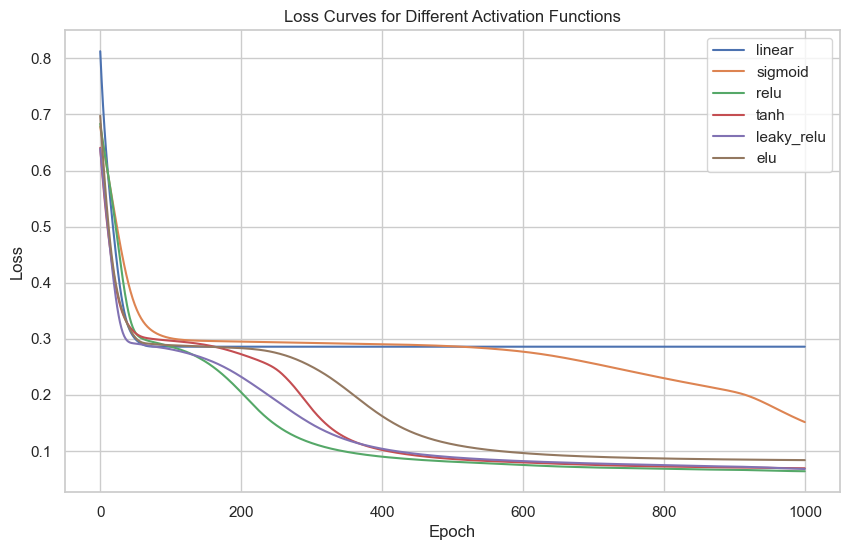

Activation: linear, Test Accuracy: 0.86, Training Time: 0.21 seconds
Activation: sigmoid, Test Accuracy: 0.96, Training Time: 0.22 seconds
Activation: relu, Test Accuracy: 0.99, Training Time: 0.20 seconds
Activation: tanh, Test Accuracy: 0.98, Training Time: 0.23 seconds
Activation: leaky_relu, Test Accuracy: 0.99, Training Time: 0.19 seconds
Activation: elu, Test Accuracy: 0.97, Training Time: 0.21 seconds


In [40]:
from torch import optim
from torchvision import transforms
from trainers import *
from networks import *
from metrics import *

X_train_tensor, X_test_tensor, y_train_tensor, y_test_tensor,X_train, X_test, y_train, y_test, X, y  = get_data()
# Activation functions to test (defined above)
activation_functions = {
    'linear': linear,
    'sigmoid': sigmoid,
    'relu': relu,
    'tanh': tanh,
    'leaky_relu': leaky_relu,
    'elu': elu
}

results = {}

for name, activation in activation_functions.items():
    model, train_losses, accuracy, training_time, decision_threshold = train(SimpleNN(activation=activation), name, X_train_tensor, X_test_tensor, y_train_tensor, y_test_tensor, X_train, X_test, y_train, y_test, epoch=1000 )
    # Store results
    results[name] = {
        'model': model,
        'train_losses': train_losses,
        'accuracy': accuracy,
        'training_time': training_time
    }

evaluateNN(results, X, y)


---
**Task 3 (medium): Evaluate👩‍💻💡**
1. Evaluate the performance of the models based on the activation functions used. Analyze the results using the plots and relate them to theoretical concepts to interpret the outcomes.
2. Evaluate the activation functions in terms of computational efficiency and their suitability for the given problem. Explain which activation function is preferred and justify the choice.
3. Rerun the experiment by increasing the number of epochs to 1000. Investigate the training curves and analyze the results. Discuss why some activation functions cause the learning  to plateau before eventually converging to a smaller loss?


---

In [41]:
# epoch: passes through the dataset
# smooth gradient: gradient that doesn't have sudden changes in value
# Smooth gradients help the model converge faster because the gradient values are more predictable and do not cause sharp jumps in weight updates.



# For epoch 300
## Evaluate the performance based on the activation function used
# Linear: Poor prediction due to non-linearity
# Sigmoid: Poor performance. Might be due to vanishing gradient problem, where it can get stuck in a local minimum
# ReLU: Poor performance. Might be due to dead neurons, limiting the model's ability to learn for negative values
# Leaky ReLU: Poor performance. 
# Tanh: Tanh performs well with good accuracy. It is able to learn the data well
# ELU: ELU performs well with good accuracy. It is able to learn the data well. Has smoother gradient compared to ReLU

## Evaluate in terms of computational efficiency
# All have similar training times
# Sigmoid and Tanh involves exponential computations, which is computationally expensive




# For epoch 1000
## Evaluate the performance based on the activation function used
# Linear: Poor prediction due to non-linearity. Plateaues early because it cant optimize
# Sigmoid: More accurate than epoch 300, but still not as good as other activation functions. Plateaues early because it cant optimize (vanishing gradient)
# ReLU: Best accuracy. Fast convergence but keeps optimizing until then
# Leaky ReLU: Good accuracy
# Tanh: Best accuracy. Smooth convergence
# ELU: Good accuracy

## Evaluate in terms of computational efficiency
# All activation functions have similar training times (~0.20–0.23 seconds). 
# This indicates that activation functions with additional computations (e.g., ELU, Tanh) do not impose significant overhead for this small dataset.
# It becomes more computationally expensive with more epochs, but with increased accuracy for most models

## Loss Functions
The loss function evaluates how closely the model’s predictions match the true labels and guides the adjustment of model parameters during training. Different types of problems require specific loss functions. Therefore, understanding the data and the problem is crucial for selecting or designing the most suitable loss function for training the network.
This exercise explores the impact of the following loss functions:
**Classification**
- Binary Cross Entropy (BCE)

**Regression**
- Mean Squared Error (MSE)
- Mean Absolute Error (MAE)


---
**Task 4 (medium): Implement loss functions👩‍💻**
1. Implement the loss functions defined below using the `torch`
 library.


**Loss functions**
Let:
- $ y_i $ be the true value of the $i$-th sample in the training set, 
- $ N $ be the number of samples.

Define:
**Mean Squared Error (MSE)**

$$
\text{MSE}(y, \hat{y}) = \frac{1}{N} \sum_{i=1}^{N} (y_i - \hat{y}_i)^2
$$
where $ \hat{y}_i $ is the predicted value of the $i$-th sample in the training set.
**Mean Absolute Error**

$$
\text{MAE}(y, \hat{y}) = \frac{1}{N} \sum_{i=1}^{N} |y_i - \hat{y}_i|
$$
where $ \hat{y}_i $ is the predicted value of the $i$-th sample in the training set.. 
**Binary Cross-Entropy Loss (BCE)**

$$
\text{BCE}(y, \hat{y}) = - \frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]
$$
where $ \hat{y}_i $ is the predicted probability of the $i$-th sample in the training set.


---

In [50]:
# Custom Binary Cross-Entropy Loss Function
# Assumes that the model outputs a probability between 0 and 1 (^y)
import re


class BCE_Loss(nn.Module):
    def __init__(self):
        super(BCE_Loss, self).__init__()

    def forward(self, outputs, targets):
        epsilon = 1e-12 # small constant to prevent log(0)
        outputs = torch.clamp(outputs, min=epsilon, max=1-epsilon) # clamp to prevent log(0)
        loss = -1 * (targets * torch.log(outputs) + (1 - targets) * torch.log(1 - outputs))
        return loss.mean()

            

# Custom Mean Squared Error Loss Function
class MSE_Loss(nn.Module):
    def __init__(self):
        super(MSE_Loss, self).__init__()

    def forward(self, outputs, targets):
        return (outputs - targets).pow(2).mean()


# Custom Mean Absolute Error Loss Function
class MAE_Loss(nn.Module):
    def __init__(self):
        super(MAE_Loss, self).__init__()

    def forward(self, outputs, targets):
        return torch.abs(outputs - targets).mean()


---
**Task 5 (medium): Visualizing loss functions👩‍💻**
1. Complete the cell below to visualize the  `BCE`
, `MSE`
 and `MAE`
 loss functions when applied to a synthetic binary classification problem. Use the implemented loss functions, the true labels and the `linspace`
 in a for loop, to plot the loss functions.
2. Use the plots and the definitions of the loss functions to argue why `BCE`
 is preferred for classification problems. 


---

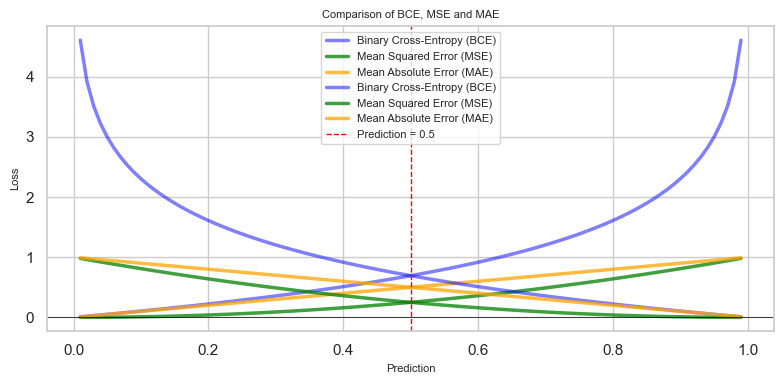

In [51]:
import seaborn as sns

# Instantiate the loss functions
bce_loss = BCE_Loss()
mse_loss = MSE_Loss()
mae_loss = MAE_Loss()

# True label
y_true = torch.tensor([0.0, 1.0])  # True labels 0 and 1

# Range of predictions
predictions = torch.tensor(np.linspace(0.01, 0.99, 100)) # all values between 0.01 and 0.99

# Plot using Seaborn
plt.figure(figsize=(8, 4))

for i in y_true: # for each label (0 and 1)
    # Compute BCE and MSE using the defined classes

    bce_values = []
    mse_values = []
    mae_values = []
    
    for prediction in predictions:
        prediction = torch.tensor([prediction]) # prediction is the range of values between 0.01 and 0.99
        target = torch.tensor([i]) # target is the label (0 or 1)
        bce_values.append(bce_loss(prediction, target).item())
        mse_values.append(mse_loss(prediction, target).item())
        mae_values.append(mae_loss(prediction, target).item())
        

    # Set Seaborn style
    sns.set(style="whitegrid")

    # Create a DataFrame for plotting
    import pandas as pd
    data = pd.DataFrame({
        'Prediction': predictions,
        'Binary Cross-Entropy (BCE)': bce_values,
        'Mean Squared Error (MSE)': mse_values,
        'Mean Absolute Error (MAE)': mae_values
    })



    # Plot BCE
    sns.lineplot(data=data, x='Prediction', y='Binary Cross-Entropy (BCE)', color='blue', label='Binary Cross-Entropy (BCE)', linewidth=2.5, alpha=0.5)

    # Plot MSE
    sns.lineplot(data=data, x='Prediction', y='Mean Squared Error (MSE)', color='green', label='Mean Squared Error (MSE)', linewidth=2.5, alpha=0.75)

    # Plot MAE
    sns.lineplot(data=data, x='Prediction', y='Mean Absolute Error (MAE)', color='orange', label='Mean Absolute Error (MAE)', linewidth=2.5, alpha=0.75)

# Add labels, title, and legend
plt.title('Comparison of BCE, MSE and MAE', fontsize=8)
plt.xlabel('Prediction', fontsize=8)
plt.ylabel('Loss', fontsize=8)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0.5, color='red', linestyle='--', linewidth=1.0, label='Prediction = 0.5')
plt.legend(fontsize=8)
plt.grid(True)

plt.tight_layout()
plt.show()

In [75]:
## Argue why BCE is better for classification tasks
# BCE is designed for probability outputs between 0 and 1, which is suitable for binary classification tasks.
# BCE penalizes heavily (exponentially) the predictions that are far from the true label
# Fx. if the true label is 1 and the prediction is close to 0, the penalty is high
# This means the model learns to adjust better 
# Also has a steep gradient near the decision boundary, compared to MSE and MAE

## Other loss functions like MSE and MAE also penalize harder (quadratically) for confidently wrong predistions, but not as much as BCE

The next step is about using the loss functions for training a neural network on the same classification task as before and to show the impact of the loss functions on performance metrics, such as accuracy, precision, recall and F1 score.
For this task, the `evaluateNN2`
 function in the `metrics.py`
 file will be used. Note the noise parameter in the `get_data`
 function and the `decision_threshold`
 in the `train`
 function.

---
**Task 6 (medium): Experiment with loss functions💡**
1. Run the cell below to train and visualize the performance of the network with the different loss functions.
2. Compare the results to the previous tasks and relate them to theory. 


---

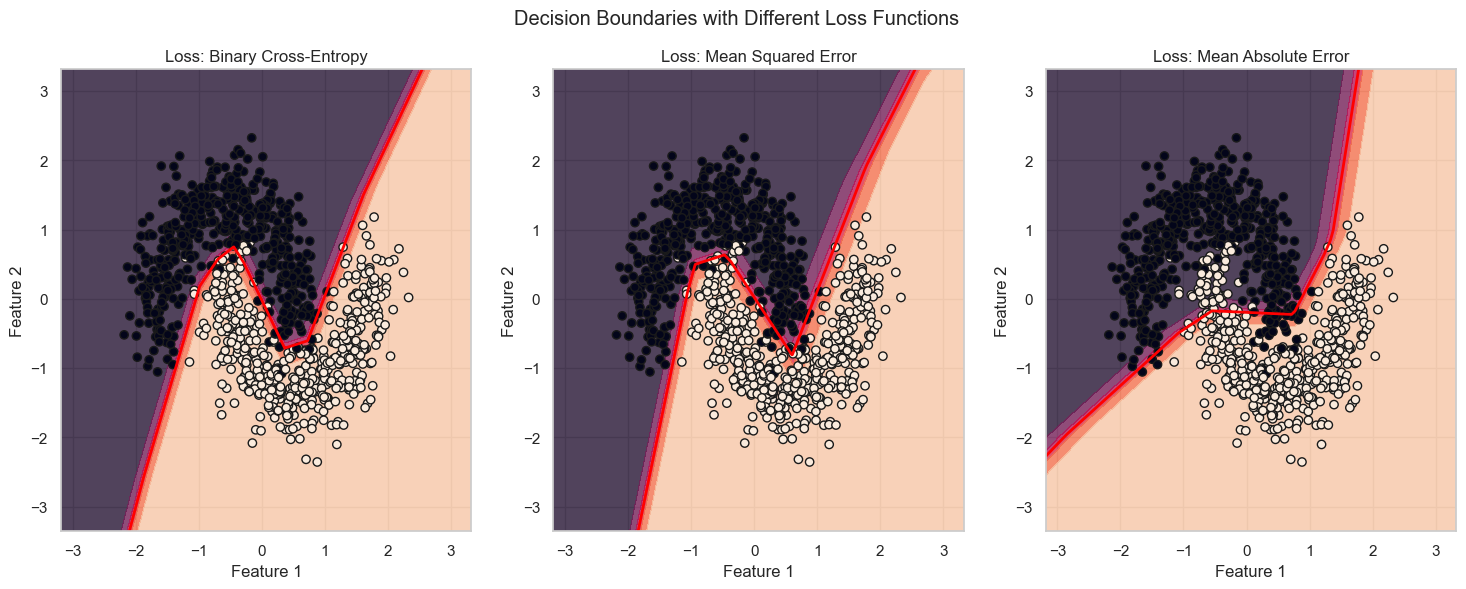

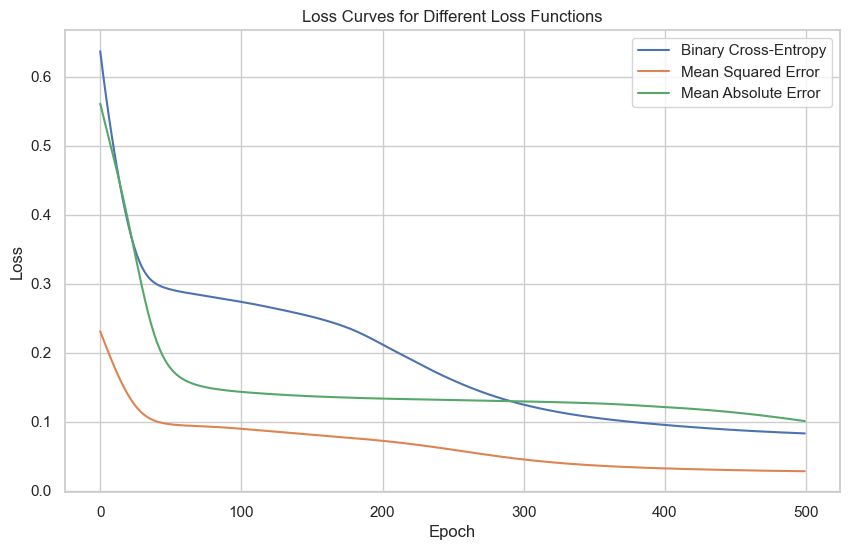

Loss: Binary Cross-Entropy, Test Accuracy: 0.98, Precision: 0.98, Recall: 0.98, F1 Score: 0.98
Loss: Mean Squared Error, Test Accuracy: 0.97, Precision: 0.97, Recall: 0.98, F1 Score: 0.98
Loss: Mean Absolute Error, Test Accuracy: 0.89, Precision: 0.92, Recall: 0.85, F1 Score: 0.89


In [118]:
from torch import optim
from torchvision import transforms
from trainers import *
from networks import *
from metrics import *


X_train_tensor, X_test_tensor, y_train_tensor, y_test_tensor,X_train, X_test, y_train, y_test, X, y  = get_data(0.2)

# Define loss functions to test
loss_functions = {
    'Binary Cross-Entropy': BCE_Loss(),
    'Mean Squared Error': MSE_Loss(),
    'Mean Absolute Error': MAE_Loss()
}

results = {}

for name, loss in loss_functions.items():
    model, train_losses, accuracy, training_time, decision_threshold = train(SimpleNN(activation=relu), name, X_train_tensor, X_test_tensor, y_train_tensor, y_test_tensor, X_train, X_test, y_train, y_test, 500, loss=loss, decision_threshold=0.5 )
    # decision_threshold: probability threshold to classify the output as 1
    # noise: adds random data to the training data
    
    # Store results
    results[name] = {
        'model': model,
        'train_losses': train_losses,
        'accuracy': accuracy,
        'training_time': training_time,
        'decision_threshold': decision_threshold
    }

evaluateNN2(results, X, y, X_test_tensor, y_test)


---
**Task 7 (medium): Evaluate💡**
1. Use the plots to evaluate the performance of the different loss functions and incorporate theoretical concepts to interpret the results.

2. Explain why MSE and MAE losses may achieve lower final loss values, while BCE delivers comparable or superior accuracy for the classification task. Discuss the distinct characteristics of each loss function and how they relate to classification performance.

3. Experiment with the noise parameter and explain its impact on accuracy. Relate your explanation to the findings from [Task 5](#loss1).

4. Modify the decision threshold and analyze its impact on the results. Address the following questions:
    - Explain a scenario where increasing the threshold might be beneficial, and support the reasoning with theory.
    - Explain a scenario where decreasing the threshold might be advantageous, and provide a theoretical justification.




---

In [ ]:
# Accuracy: The proportion of all predictions (both positive and negative) that are correct.
# Precision: Of all the predictions made as positive (1), how many are actually correct.
# Recall (Sensitivity): Of all actual positive cases, how many did the model correctly identify.
# F1 Score: The harmonic mean of precision and recall, balancing the two.


## 1: Performance of loss functions
# Binary Cross-Entropy: Best accuracy, smooth and fast convergence
## The decision boundary follows the data distribution well
# Mean Squared Error: Good accuracy, low loss
## The decision boundary is not as smooth as BCE
# Mean Absolute Error: Poor accuracy, high loss, does not fit the data well, due to its linear penalty

## 2: Why does MSE and MAE sometimes have lower loss than BCE?
# MSE has lower loss than BCE, even though BCE captures the data distribution better
# BCE has higher penalty for wrong predictions, which is why it has higher loss
# The high loss values for BCE forces the model to adjust early on, which is why it has better accuracy

# 3: Noise impact on accuracy: 
# When there is little/no noise, the data is well-seperated, giving higher accuracy for all loss functions
# With more noise, it is harder for the model especially for MAE, which has the lowest accuracy
# Here BCE has the highest accuracy because it penalizes the model more for wrong predictions, forcing it to adjust better
# But with a lot of noise (0.5+) the data might overlap too much. 
# In one case it gave better accuracy for MAE, beacuse the data distribution became almost linear, which is what MAE is good at

# 4: Decision threshold impact:
# The decision threshold is the probability threshold to classify the output as 1 (positive)
# How to decide the threshold depends on the tolerance for false positives and false negatives

# Beneficial with low decision threshold: 
# Model becomes less strict with classifying the output as 1
# Gives high recall, but low precision
# Example: In coronavirus testing, you want to catch as many positive cases as possible, even if it means some false positives

# Beneficial with high decision threshold:
# Model becomes stricter with classifying the output as 1 (it needs to be more confident)
# Gives high precision, but low recall
# Example: In spam detection, it is better to overlook some spam emails than to classify important emails as spam


---
**Task 8 (hard): Custom loss functions💡**
Consider the case of iris codes derived from an individual’s iris pattern. The codes are represented as binary vectors which is matched against a database of authorized codes to determine access. The Hamming Distance (HD) is commonly used as a similarity measure.

$$
HD(\mathbf{x}, \mathbf{y}) = \sum_{i=1}^{n} 
\begin{cases} 
1 & \text{if } x_i \neq y_i \\
0 & \text{if } x_i = y_i 
\end{cases}
$$
**It calculates the number of positions with different values.**
A neural network could potentially be trained to generate synthetic eye images embedding specific iris codes, potentially to gain unauthorized access to a system. It may seem logical to design a custom loss function based on the Hamming Distance, encouraging the network to generate patterns closely matching a target iris code. However, this approach is not valid for a loss function in the context of neural network training.
1. Argue why the HD is not a valid choice as loss function.


**Hint**
Incoorporate the formula of the HD and the nature of Gradient Decent in your discussion.


---

In [ ]:
# Hamming Distance (HD) is not a valid loss function because:
# 1. HD is non-differentiable: It uses discrete comparisons (1 or 0), making it unsuitable for gradient-based optimization.
# 2. Gradients are undefined: Neural networks require continuous loss functions to compute meaningful weight updates.
# 3. Discrete outputs: Neural networks produce continuous outputs during training, but HD operates on binary vectors, creating discontinuity.
# Use differentiable alternatives like Binary Cross-Entropy (BCE) or Mean Absolute Error (MAE) for effective training.

# Its loss is either 0 or 1 for each comarison, giving the loss curve a step-like shape, not optimal for gradient descent